# Investigação da membrana passiva — Experimentos 1 e 2
**Equipe:** Ane Aille, Anna Caroline Barbosa, Guilherme Ribeiro e Shara Isabell.
**Data:** 20/10/26

Neste notebook, você vai testar como **capacitância** e **resistência** modificam a resposta de uma membrana passiva à mesma corrente. Registre suas previsões **antes** de executar cada experimento e suas observações após visualizar os resultados.

## Objetivos
- Distinguir velocidade de resposta e amplitude final.
- Comparar subida e retorno ao repouso.
- Relacionar as curvas a $\tau_m=R_mC_m$ e $\Delta V_\infty=R_m I$.

## Como trabalhar
Complete os trechos marcados com `TODO`. Os códigos estão propositalmente incompletos: `None` e `NotImplementedError` indicam tarefas a realizar. Execute as células em ordem depois de completá-las. Escreva nas áreas **Resposta** das células Markdown. Não há limiar, reset nem geração de potenciais de ação neste modelo.

## 1. Modelo e convenções
$$C_m\frac{dV_m}{dt}=-\frac{V_m-E_L}{R_m}+I_{\mathrm{ext}}(t).$$
A corrente externa positiva entra na célula; a corrente de fuga positiva sai dela. No modelo com uma única corrente de fuga, o repouso é $E_L$.

Pelo método de Euler:
$$V_{k+1}=V_k+\frac{\Delta t}{C_m}\left[-\frac{V_k-E_L}{R_m}+I_k\right].$$

**Unidades:** faça os cálculos no SI (V, A, Ω, F e s). Converta apenas para apresentar os gráficos.

| Grandeza | Conversão para SI |
|---|---|
| mV | multiplicar por $10^{-3}$ |
| pA | multiplicar por $10^{-12}$ |
| MΩ | multiplicar por $10^6$ |
| pF | multiplicar por $10^{-12}$ |
| ms | multiplicar por $10^{-3}$ |

### Condição de referência
$E_L=V_m(0)=-70$ mV; $R_m=100$ MΩ; $C_m=100$ pF; corrente de 200 pA aplicada de 10 a 110 ms; simulação até 210 ms; passo de 0,1 ms.

O pulso será ativo para $10\leq t<110$ ms. A duração permite aproximar o equilíbrio; o valor no final do pulso ainda é uma aproximação, não o limite matemático exato.

In [4]:

import numpy as np
import matplotlib.pyplot as plt

# TODO: converter os parâmetros para o SI.
E_L = -70e-3       # -70 mV em V
R_ref = 100e6     # 100 MΩ em Ω
C_ref = 100e-12     # 100 pF em F
I_amp = 200e-12     # 200 pA em A
dt = 0.1e-3        # 0,1 ms em s
t_total = 210e-3   # 210 ms em s = Duração Total da simulação
t_on = 10e-3       # 10 ms em s = Instante em que a corrente começa.
t_off = 110e-3     # 110 ms em s = Instante em que a corrente termina.

# TODO: criar o vetor de tempo, incluindo t=0 e o tempo final.
n_steps = int(round(t_total / dt)) #Calcula quantidade de passos.
t = np.arange(n_steps + 1) * dt #Cria sequência de int de 0 até 2100

# TODO: criar um vetor de zeros e preencher o intervalo do pulso.
I_ext = np.zeros_like(t) #Cria vetor de zeros com o mesmo tamanho do vetor t.

#Convertem os instantes de início e fim em índices do vetor.
idx_on = int(round(t_on / dt)) 
idx_off = int(round(t_off / dt))

#Aplica a corrente.
I_ext[idx_on:idx_off] = I_amp


ImportError: Matplotlib requires numpy>=1.25; you have 1.24.3

### Verifique a entrada antes de simular
Represente a corrente aplicada em função do tempo. Use ms no eixo horizontal e pA no vertical.

**Pergunta:** em quais instantes a corrente muda? Qual é o valor fora do pulso?

**Resposta:** A corrente externa muda em 10 ms, quando passa de 0 para 200 pA, e em 110 ms, quando retorna para 0 pA. Fora do pulso, a corrente externa é nula.
Quando a corrente externa é desligada, ela se torna zero, mas a corrente de fuga pode continuar existindo, fazendo o potencial retornar ao repouso.

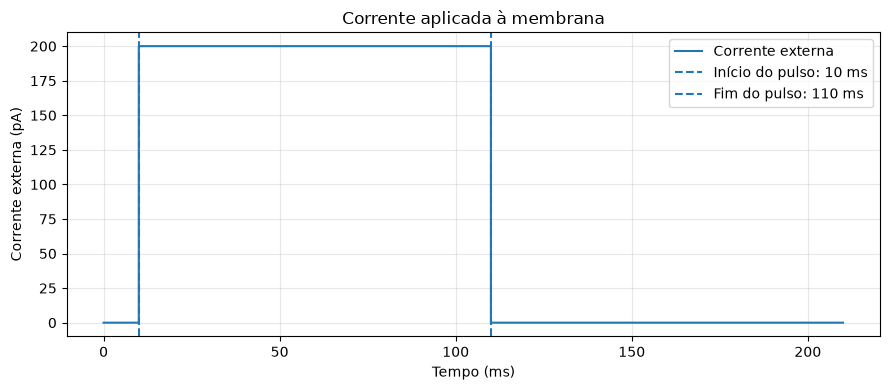

In [ ]:

# TODO: plotar t em ms e I_ext em pA.
# Adicionar rótulos, título e marcar o início e o fim do pulso.

plt.figure(figsize=(9, 4))

#Representa a corrente ao longo do tempo.
plt.step(t * 1e3, I_ext * 1e12, where="post",
         label="Corrente externa")
plt.axvline(t_on * 1e3, linestyle="--",
            label="Início do pulso: 10 ms")
plt.axvline(t_off * 1e3, linestyle="--",
            label="Fim do pulso: 110 ms")

plt.xlabel("Tempo (ms)")
plt.ylabel("Corrente externa (pA)")
plt.title("Corrente aplicada à membrana")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


## 2. Construindo a função de simulação
Implemente uma função reutilizável. Ela deve criar o vetor de potencial, definir sua condição inicial e percorrer os passos de tempo. Em cada passo, calcule a corrente de fuga e depois atualize o potencial pela equação de Euler.

Use a corrente do instante k para calcular o potencial do instante k+1.

In [ ]:

def simular_membrana(t, corrente, R_m, C_m, E_L, V_inicial):
    """Retorna o potencial em V; todas as entradas devem estar no SI."""

    # TODO: criar V com o mesmo comprimento de t. (Vetor Potencial)
    V = np.zeros_like(t, dtype=float)

    # TODO: definir V[0] = V_inicial. (Potencial Inicial)
    V[0] = V_inicial

    # TODO: percorrer k de 0 até len(t)-2.
    #       calcular h = t[k+1] - t[k].
    #       calcular I_fuga = (V[k] - E_L) / R_m.
    #       calcular V[k+1] pela atualização de Euler.

    #Calcula potencial nos instantes seguintes
    for k in range(len(t) - 1):
        # Intervalo entre dois instantes consecutivos
        h = t[k + 1] - t[k]
        #Corrente de fuga no instante atual
        I_fuga = (V[k] - E_L) / R_m
        # Atualizacao do potencial pelo metodo de Euler
        V[k + 1] = V[k] + (h / C_m) * (
            -I_fuga + corrente[k]
        )

    # TODO: retornar V. (Potencial Calculado)
    return V

    #O passo é de 0,1ms


## 3. Experimento 1 — Alterando a capacitância
**Pergunta:** como aumentar $C_m$ modifica a resposta à mesma corrente?

Compare **100 pF e 200 pF**, mantendo $R_m=100$ MΩ, $E_L$, a condição inicial e o pulso de corrente constantes.

Aumentar C_m torna a resposta mais lenta sem alterar a amplitude final. Com R_m e a corrente constantes, a variação final (ΔV∞ = R_m·I = 20 mV, equilíbrio em −50 mV) é a mesma para 100 e 200 pF. Já a constante de tempo (τ = R_m·C_m) dobra, de 10 ms para 20 ms: a membrana com maior capacitância precisa acumular mais carga para mudar o potencial, então sobe mais devagar durante o pulso e retorna mais devagar ao repouso após o desligamento

### Previsões — antes de executar
1. Qual condição deve apresentar maior constante de tempo? Justifique.
2. As condições devem chegar ao mesmo equilíbrio ou a equilíbrios diferentes?
3. Qual condição deve retornar mais lentamente ao repouso?

**Resposta 1:** A condição de 200 pF, porque τ = Rm·Cm e, com Rm fixo, dobrar a capacitância dobra a constante de tempo (20 ms contra 10 ms). Um balde maior precisa de mais carga para mudar o potencial, então responde mais devagar.

**Resposta 2:** As condições devem chegar ao mesmo equilíbrio, porque ΔV∞ = Rm·I depende só da resistência e da corrente, e não da capacitância. A capacitância só muda o tempo para chegar lá.

**Resposta 3:** A condição de 200 pF, porque tem maior constante de tempo (τ = 20 ms contra 10 ms). O retorno ao repouso também acontece na escala de τ, então com a capacitância maior o retorno é mais lento.

### Calcule as previsões
Complete a tabela usando $\tau_m=R_mC_m$, $\Delta V_\infty=R_mI$ e $V_\infty=E_L+\Delta V_\infty$.

| Capacitância | Constante de tempo (ms) | Variação final prevista (mV) | Equilíbrio previsto (mV) |
|---|---|---|---|
| 100 pF | 10|20 |-50 |
| 200 pF | 20|20 |-50 |

In [ ]:
# TODO: definir as duas capacitâncias em F.
# TODO: para cada capacitância, simular com R_ref e armazenar a curva.
# Sugestão: resultados_exp1[C_m] = curva de potencial.
# TODO: calcular e apresentar tau, delta_V_final e V_equilibrio previstos.

capacitancias = [100e-12, 200e-12] #valor de 100pF e 200pF em F
resultados_exp1 = {}

for C_m in capacitancias:
    resultados_exp1[C_m] = simular_membrana(t, I_ext, R_ref, C_m, E_L, E_L)

    # previsões teóricas
    tau = R_ref * C_m                    # em s
    delta_V_final = R_ref * I_amp        # em V
    V_equilibrio = E_L + delta_V_final   # em V

    print(f"Cm = {C_m*1e12:.0f} pF")
    print(f"  tau = {tau*1e3:.1f} ms")
    print(f"  delta_V_final = {delta_V_final*1e3:.1f} mV")
    print(f"  V_equilibrio = {V_equilibrio*1e3:.1f} mV")
    



Cm = 100 pF
  tau = 10.0 ms
  delta_V_final = 20.0 mV
  V_equilibrio = -50.0 mV
Cm = 200 pF
  tau = 20.0 ms
  delta_V_final = 20.0 mV
  V_equilibrio = -50.0 mV


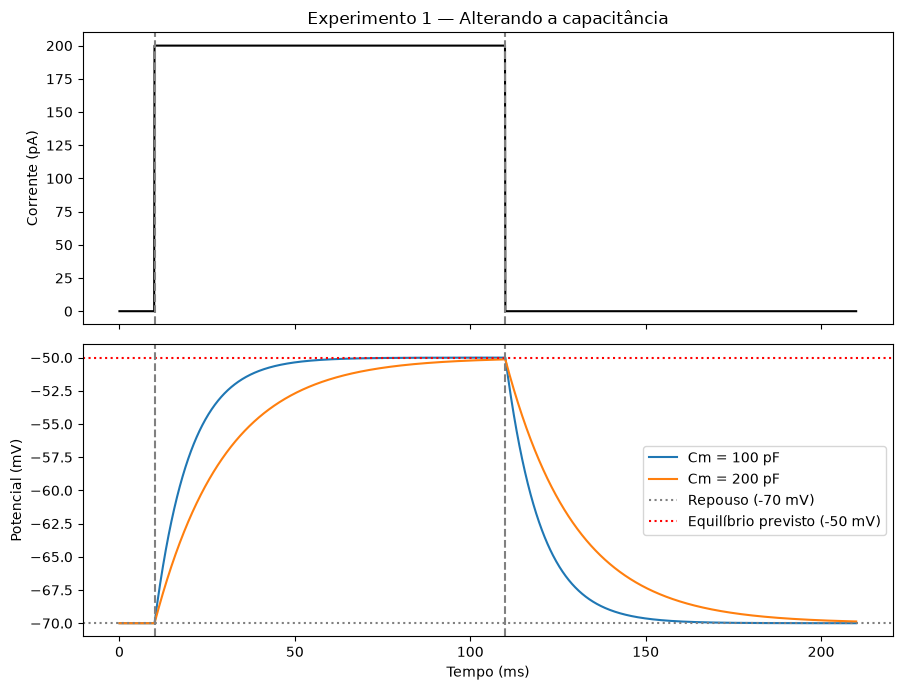

In [ ]:
# TODO: criar dois gráficos alinhados e com eixo de tempo compartilhado:
# 1. corrente aplicada (pA);
# 2. as duas curvas de potencial (mV).
# Incluir legendas com C_m, rótulos, repouso e equilíbrio previsto.
# Marcar t_on e t_off. Usar a mesma escala para ambas as curvas.


fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(9, 7))
t_ms = t * 1e3

# 1. Corrente aplicada
ax1.plot(t_ms, I_ext * 1e12, color="black")
ax1.set_ylabel("Corrente (pA)")
ax1.set_title("Experimento 1 — Alterando a capacitância")

# 2. Potencial das duas condições
for C_m, V in resultados_exp1.items():
    ax2.plot(t_ms, V * 1e3, label=f"Cm = {C_m*1e12:.0f} pF")

ax2.axhline(E_L * 1e3, color="gray", linestyle=":", label="Repouso (-70 mV)")
ax2.axhline((E_L + R_ref * I_amp) * 1e3, color="red", linestyle=":",
            label="Equilíbrio previsto (-50 mV)")
ax2.set_ylabel("Potencial (mV)")
ax2.set_xlabel("Tempo (ms)")
ax2.legend()

# Início e fim do pulso nos dois gráficos
for ax in (ax1, ax2):
    ax.axvline(t_on * 1e3, color="gray", linestyle="--")
    ax.axvline(t_off * 1e3, color="gray", linestyle="--")

plt.tight_layout()
plt.show()


### Observações — Experimento 1
1. As curvas se aproximam do mesmo potencial? Compare com sua previsão.
2. Em qual condição a subida é mais rápida? Use uma evidência do gráfico.
3. Estime o tempo para atingir 63,2% da mudança prevista, **contado a partir do início da corrente**. Compare com $R_mC_m$.
4. Após desligar a corrente, qual curva retorna mais lentamente? Há um salto no potencial?
5. Explique por que aumentar a capacitância modifica a velocidade, mas não a variação final neste experimento.

**Resposta 1:** Sim. As duas curvas tendem à linha de −50 mV, como previsto, a de 200 pF só chega mais devagar. Antes do desligamento, os valores são −50,00 mV (100 pF) e −50,13 mV (200 pF). 

**Resposta 2:** A de 100 pF: a curva azul sobe mais rápida e encosta em −50 mV por volta de 50 ms, enquanto a de 200 pF ainda está visivelmente abaixo (cerca de −52,7 mV)

**Resposta 3:** O alvo de 63,2% é −57,36 mV (a subida total é de 20 mV). A curva de 100 pF chegou nele 10,0 ms após o início do pulso e a de 200 pF, 20,0 ms após, valores iguais a $R_mC_m$ (10 ms e 20 ms). Isso acontece porque, em um tempo igual a $\tau$, a curva sempre completa 63,2% da subida, então esse tempo estima $\tau$..

**Resposta 4:** A de 200 pF volta mais devagar, em t = 160 ms está em cerca de −68,4 mV, contra −69,9 mV da de 100 pF. Não há salto, as curvas são contínuas em 110 ms e só mudam de direção.

**Resposta 5:** Com a capacitÂncia maior, a membrana precisa de mais carga para mudar o potencial, então demora mais ($\tau$ maior). Já o equilíbrio é onde a fuga iguala a corrente aplicada, e isso depende só de $R_m\cdot I$, não de $C_m$

| Capacitância | Tempo estimado até 63,2% (ms) | Potencial imediatamente antes do desligamento (mV) |
|---|---|---|
| 100 pF | 10,0 | −50,00 |
| 200 pF | 20,0 | −50,13 |

**Dica:** o alvo é $E_L+0{,}632\,\Delta V_\infty$. Use o primeiro instante durante o pulso em que a curva alcança esse alvo e subtraia $t_{\mathrm{on}}$.

In [ ]:
# TODO: extrair as medidas do Experimento 1.
# Para cada curva: calcular o alvo de 63,2%, localizar seu primeiro
# cruzamento durante o pulso e medir o tempo desde t_on.
# Registrar também V no último ponto anterior a t_off.

alvo = E_L + 0.632 * (R_ref * I_amp)     # alvo de 63,2% (em V)

i_on = int(round(t_on / dt))
i_off = int(round(t_off / dt))

for C_m, V in resultados_exp1.items():
    # primeiro ponto, durante o pulso, em que V alcança o alvo
    idx = i_on + np.argmax(V[i_on:i_off] >= alvo)
    tempo_63 = (t[idx] - t_on) * 1e3     # ms, contado a partir de t_on
    V_antes = V[i_off - 1] * 1e3         # mV, último ponto antes de t_off

    print(f"Cm = {C_m*1e12:.0f} pF | tempo até 63,2% = {tempo_63:.1f} ms | "
          f"V antes do desligamento = {V_antes:.2f} mV")


Cm = 100 pF | tempo até 63,2% = 10.0 ms | V antes do desligamento = -50.00 mV
Cm = 200 pF | tempo até 63,2% = 20.0 ms | V antes do desligamento = -50.13 mV


## 4. Experimento 2 — Alterando a resistência
**Pergunta:** como aumentar $R_m$ modifica a amplitude e a escala temporal da resposta?

Compare **100 MΩ e 200 MΩ**, mantendo $C_m=100$ pF, $E_L$, a condição inicial e o mesmo pulso de corrente constantes.

### Previsões — antes de executar
1. Qual condição deve produzir maior variação de potencial em regime estacionário?
2. Qual condição deve apresentar maior constante de tempo?
3. Partindo de $V_m(0)=E_L$, a inclinação inicial da resposta deve mudar? Examine a equação: no início do pulso, a corrente de fuga é zero.

**Resposta 1:** A de 200 MΩ. Pela fórmula ΔV∞ = Rm·I, dobrar a resistência dobra a variação: 40 mV contra 20 mV. Com mais resistência, a membrana deixa escapar menos corrente, então o potencial sobe mais.

**Resposta 2:** A condição de 200 MΩ. Como τ = Rm·Cm e Cm está fixo em 100 pF, dobrar a resistência dobra a constante de tempo: 20 ms contra 10 ms.

**Resposta 3:** Não muda. No início, Vm = E_L, então ainda não há corrente de fuga. Toda a corrente vai para o capacitor, e a inclinação é I/Cm = 2 mV/ms nas duas condições. A resistência só faz diferença depois, quando o potencial começa a subir.

| Resistência | Constante de tempo (ms) | Variação final prevista (mV) | Equilíbrio previsto (mV) |
|---|---|---|---|
| 100 MΩ | 10 | 20 | −50 |
| 200 MΩ | 20 | 40 | −30 |

**Interpretação:** maior constante de tempo significa maior tempo para percorrer a mesma **fração da própria resposta**. Compare também a amplitude: as curvas não têm o mesmo equilíbrio.

In [ ]:
# TODO: definir as duas resistências em Ω.
resistencias = [100e6, 200e6]  # 100 MΩ e 200 MΩ em Ω
resultados_exp2 = {}

# TODO: para cada resistência, simular com C_ref e armazenar a curva.
# Sugestão: resultados_exp2[R_m] = curva de potencial.
# TODO: calcular e apresentar tau, delta_V_final e V_equilibrio previstos.

for R_m in resistencias:
    # Mesma corrente, mesma capacitância (C_ref) e mesma condição inicial (E_L)
    resultados_exp2[R_m] = simular_membrana(t, I_ext, R_m, C_ref, E_L, E_L)

    # previsões teóricas
    tau = R_m * C_ref                    # em s
    delta_V_final = R_m * I_amp          # em V
    V_equilibrio = E_L + delta_V_final   # em V

    print(f"Rm = {R_m*1e-6:.0f} MΩ")
    print(f"  tau = {tau*1e3:.1f} ms")
    print(f"  delta_V_final = {delta_V_final*1e3:.1f} mV")
    print(f"  V_equilibrio = {V_equilibrio*1e3:.1f} mV")

Rm = 100 MΩ
  tau = 10.0 ms
  delta_V_final = 20.0 mV
  V_equilibrio = -50.0 mV
Rm = 200 MΩ
  tau = 20.0 ms
  delta_V_final = 40.0 mV
  V_equilibrio = -30.0 mV


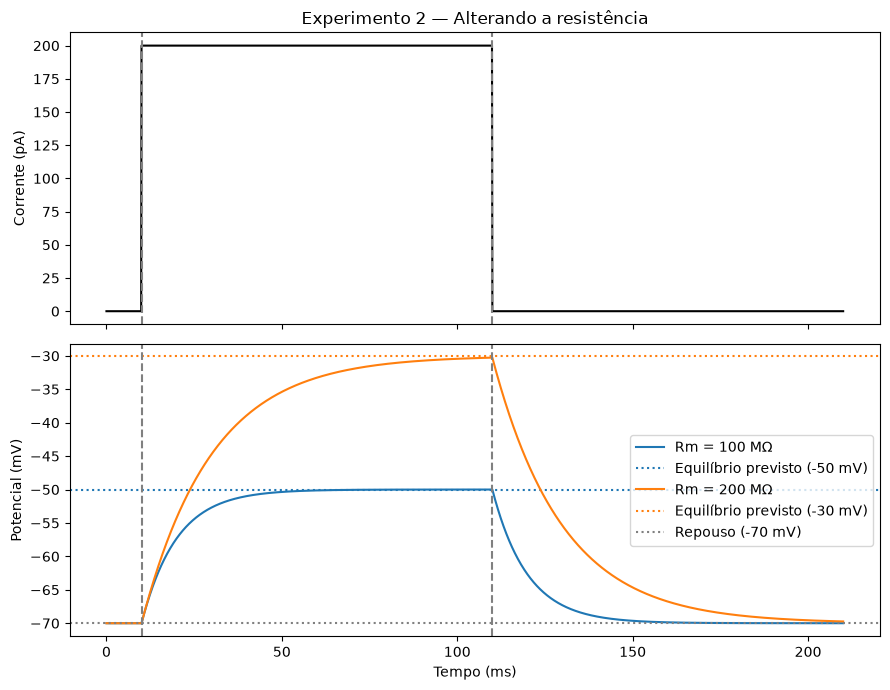

In [ ]:
# TODO: criar os gráficos de corrente e potencial, alinhados no tempo.
# Sobrepor as curvas e indicar os dois equilíbrios previstos.
# Usar legendas com R_m e marcar início/fim do pulso.
# Não usar escalas diferentes para as curvas de potencial.

fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(9, 7))
t_ms = t * 1e3
cores = {100e6: "tab:blue", 200e6: "tab:orange"}

# 1. Corrente aplicada (a mesma para as duas condições)
ax1.plot(t_ms, I_ext * 1e12, color="black")
ax1.set_ylabel("Corrente (pA)")
ax1.set_title("Experimento 2 — Alterando a resistência")

# 2. Potencial das duas condições, no MESMO eixo (mesma escala)
for R_m, V in resultados_exp2.items():
    ax2.plot(t_ms, V * 1e3, color=cores[R_m], label=f"Rm = {R_m*1e-6:.0f} MΩ")
    # equilíbrio previsto de cada condição: E_L + R_m*I
    V_eq = (E_L + R_m * I_amp) * 1e3
    ax2.axhline(V_eq, color=cores[R_m], linestyle=":",
                label=f"Equilíbrio previsto ({V_eq:.0f} mV)")

ax2.axhline(E_L * 1e3, color="gray", linestyle=":", label="Repouso (-70 mV)")
ax2.set_ylabel("Potencial (mV)")
ax2.set_xlabel("Tempo (ms)")
ax2.legend(loc="center right")

# Início e fim do pulso nos dois gráficos
for ax in (ax1, ax2):
    ax.axvline(t_on * 1e3, color="gray", linestyle="--")
    ax.axvline(t_off * 1e3, color="gray", linestyle="--")

plt.tight_layout()
plt.show()

### Observações — Experimento 2
1. Qual condição produz maior variação final? O resultado concorda com $\Delta V_\infty=R_mI$?
2. Estime o tempo para atingir 63,2% **da variação prevista de cada condição**. Qual tem maior constante de tempo?
3. Observe os primeiros passos após o início do pulso. As inclinações iniciais são semelhantes? Explique com $dV_m/dt=I/C_m$ nesse instante.
4. Qual condição retorna mais lentamente ao repouso após desligar a corrente?
5. Se a curva atingir um potencial que poderia desencadear um disparo em um neurônio real, o modelo gera um potencial de ação? Quais mecanismos estão ausentes?

**Resposta 1:** A de 200 MΩ sobe até cerca de −30 mV (39,73 mV de variação), contra −50 mV (20,00 mV) da de 100 MΩ. Concorda com $\Delta V_\infty=R_mI$ (40 mV e 20 mV); a pequena diferença é porque a curva ainda não chegou exatamente ao equilíbrio.

**Resposta 2:** 10,0 ms para 100 MΩ e 20,0 ms para 200 MΩ (alvos de −57,36 e −44,72 mV). A de 200 MΩ tem a maior constante de tempo, igual a $R_mC_m$.

**Resposta 3:** Sim, são iguais (2,00 mV/ms), e no zoom as curvas começam sobrepostas. No início não há fuga, então $dV_m/dt=I/C_m=2$ mV/ms, sem depender de $R_m$; a diferença só aparece depois.

**Resposta 4:** A de 200 MΩ ela parte de um potencial mais alto e tem $\tau$ maior. Em t = 160 ms está em cerca de −66,8 mV, contra −69,9 mV da de 100 MΩ.

**Resposta 5:** Não. O modelo é passivo, a curva só sobe suavemente e satura, sem limiar nem reset. Faltam canais de Na⁺ e K⁺ dependentes de voltagem, limiar, repolarização e período refratário.

| Resistência | Tempo estimado até 63,2% (ms) | Variação antes do desligamento (mV) | Inclinação inicial (mV/ms) |
|---|---|---|---|
| 100 MΩ | 10,0 | 20,00 | 2,00 |
| 200 MΩ | 20,0 | 39,73 | 2,00 |

Rm = 100 MΩ | alvo = -57.36 mV | tempo até 63,2% = 10.0 ms | variação antes do desligamento = 20.00 mV | inclinação inicial = 2.00 mV/ms
Rm = 200 MΩ | alvo = -44.72 mV | tempo até 63,2% = 20.0 ms | variação antes do desligamento = 39.73 mV | inclinação inicial = 2.00 mV/ms

Previsão teórica da inclinação inicial: I/C_m = 2.00 mV/ms (igual para as duas resistências)


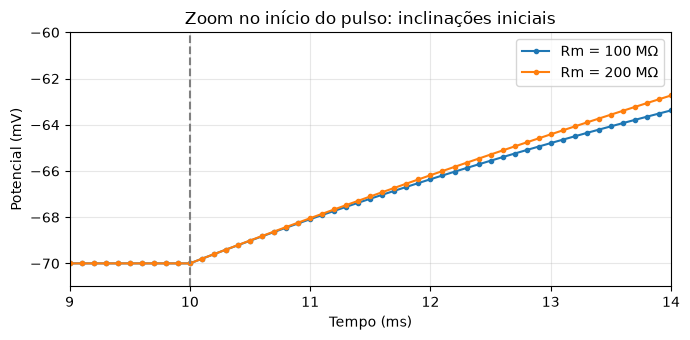

In [ ]:
# TODO: extrair as medidas do Experimento 2.
# Usar o alvo específico de cada resistência.
# Estimar a inclinação no primeiro passo após o início do pulso.
# Atenção: converter as unidades da inclinação para mV/ms.

i_on = int(round(t_on / dt))
i_off = int(round(t_off / dt))

for R_m, V in resultados_exp2.items():
    # alvo de 63,2% da variação prevista DESTA condição
    delta_V_prev = R_m * I_amp                   # em V
    alvo = E_L + 0.632 * delta_V_prev            # em V

    # primeiro ponto, durante o pulso, em que V alcança o alvo
    idx = i_on + np.argmax(V[i_on:i_off] >= alvo)
    tempo_63 = (t[idx] - t_on) * 1e3             # ms, contado a partir de t_on

    # variação acumulada no último ponto antes de t_off
    variacao_antes = (V[i_off - 1] - E_L) * 1e3  # mV

    # inclinação no primeiro passo após o início do pulso
    inclinacao_V_s = (V[i_on + 1] - V[i_on]) / dt   # em V/s
    inclinacao_mV_ms = inclinacao_V_s * 1e3 / 1e3   

    print(f"Rm = {R_m*1e-6:.0f} MΩ | alvo = {alvo*1e3:.2f} mV | "
          f"tempo até 63,2% = {tempo_63:.1f} ms | "
          f"variação antes do desligamento = {variacao_antes:.2f} mV | "
          f"inclinação inicial = {inclinacao_mV_ms:.2f} mV/ms")

print(f"\nPrevisão teórica da inclinação inicial: I/C_m = "
      f"{I_amp / C_ref * 1e3 / 1e3:.2f} mV/ms (igual para as duas resistências)")

# Zoom nos primeiros milissegundos do pulso para comparar as inclinações
plt.figure(figsize=(7, 3.5))
for R_m, V in resultados_exp2.items():
    plt.plot(t * 1e3, V * 1e3, marker=".", label=f"Rm = {R_m*1e-6:.0f} MΩ")
plt.xlim(9, 14)
plt.ylim(-71, -60)
plt.axvline(t_on * 1e3, color="gray", linestyle="--")
plt.xlabel("Tempo (ms)")
plt.ylabel("Potencial (mV)")
plt.title("Zoom no início do pulso: inclinações iniciais")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## 5. Verificação numérica
Escolha uma condição e repita a simulação com $\Delta t=0{,}05$ ms. **Reconstrua o vetor de tempo e o pulso de corrente** para esse passo.

Compare as curvas no mesmo gráfico. Para comparar valores numericamente, use instantes comuns ou interpolação.

1. A redução do passo modifica de forma relevante as conclusões?
2. Por que o passo de tempo deve ser pequeno em relação à menor constante de tempo investigada?

**Resposta 1:** Não. As duas curvas ficam sobrepostas no gráfico. A diferença máxima entre elas é de 0,019 mV (por volta de 20 ms, durante a subida, quando o erro do método já se acumulou), bem menor que os 20 mV de variação, e o tempo até 63,2% continua sendo 10,0 ms. As conclusões não mudam.

**Resposta 2:** O método de Euler trata a corrente de fuga como constante durante cada passo. Se o passo for grande perto de $\tau$, o potencial muda bastante dentro do passo e o erro cresce. Com $\Delta t=0{,}1$ ms contra $\tau=10$ ms (cerca de 1%), o erro é desprezível.

In [ ]:
# TODO: escolher R_m e C_m de uma condição já investigada.
# TODO: reconstruir t e I_ext para dt/2 e simular.
# TODO: sobrepor a curva original e a curva com passo menor.
# TODO: comparar os potenciais em instantes comuns.
# Condição escolhida: R_m = 100 MΩ e C_m = 100 pF (a de menor constante de tempo, τ = 10 ms)
R_m, C_m = R_ref, C_ref

# Simulação original (passo de 0,1 ms)
V_original = simular_membrana(t, I_ext, R_m, C_m, E_L, E_L)

# Reconstruir t e I_ext para dt/2 e simular
dt2 = dt / 2
n_steps2 = int(round(t_total / dt2))
t2 = np.arange(n_steps2 + 1) * dt2

I_ext2 = np.zeros_like(t2)
idx_on2 = int(round(t_on / dt2))
idx_off2 = int(round(t_off / dt2))
I_ext2[idx_on2:idx_off2] = I_amp

V_metade = simular_membrana(t2, I_ext2, R_m, C_m, E_L, E_L)

# Sobrepor as duas curvas
plt.figure(figsize=(9, 4))
plt.plot(t * 1e3, V_original * 1e3, label="Δt = 0,1 ms")
plt.plot(t2 * 1e3, V_metade * 1e3, "--", label="Δt = 0,05 ms")
plt.axvline(t_on * 1e3, color="gray", linestyle=":")
plt.axvline(t_off * 1e3, color="gray", linestyle=":")
plt.xlabel("Tempo (ms)")
plt.ylabel("Potencial (mV)")
plt.title("Verificação numérica: efeito de reduzir o passo")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Comparar em instantes comuns: o vetor t2 tem o dobro de pontos,
# então os pontos de índice par coincidem com os instantes de t
V_metade_comum = V_metade[::2]
diferenca = np.abs(V_original - V_metade_comum) * 1e3   # mV

i_max = np.argmax(diferenca)
print(f"Diferença máxima: {diferenca[i_max]:.4f} mV (em t = {t[i_max]*1e3:.1f} ms)")
print(f"Diferença relativa à variação total (20 mV): {diferenca[i_max]/20*100:.2f}%")

NameError: name 'R_ref' is not defined

## 6. Síntese da investigação
Complete com base nos resultados obtidos.

| Alteração | Efeito na constante de tempo | Efeito na variação final | Evidência observada |
|---|---|---|---|
| Aumentar $C_m$, com $R_m$ constante | Aumenta ($\tau=R_mC_m$ dobrou: 10 → 20 ms) | Não muda (continua 20 mV; equilíbrio em −50 mV) | Tempo até 63,2%: 10,0 ms (100 pF) e 20,0 ms (200 pF); as duas curvas tendem à mesma linha de −50 mV |
| Aumentar $R_m$, com $C_m$ constante | Aumenta ($\tau$ dobrou: 10 → 20 ms) | Aumenta ($\Delta V_\infty=R_mI$ dobrou: 20 → 40 mV) | Tempo até 63,2%: 10,0 ms e 20,0 ms; variação antes do desligamento: 20,00 mV e 39,73 mV; inclinação inicial igual (2,00 mV/ms) |

### Conclusão
Escreva um parágrafo que relacione as observações à capacitância, à resistência e ao balanço de correntes. Diferencie **previsão teórica**, **resultado da simulação** e **limitação do modelo**.

**Conclusão:** A capacitância e a resistência controlam coisas diferentes. A constante de tempo $\tau=R_mC_m$ depende das duas, então aumentar qualquer uma deixa a resposta mais lenta (na simulação, o tempo até 63,2% passou de 10 ms para 20 ms nos dois experimentos). Já a variação final $\Delta V_\infty=R_mI$ depende só de $R_m$ e de $I$: ela não mudou ao dobrar $C_m$ e dobrou (20 → 40 mV) ao dobrar $R_m$. Isso decorre do balanço de correntes: no equilíbrio, a corrente de fuga iguala a corrente aplicada, e o capacitor deixa de influenciar. A teoria previu esses valores, a simulação os reproduziu (com pequenas diferenças, como 39,73 mV em vez de 40 mV, porque 100 ms ainda não é um tempo infinito) e a verificação com passo menor mostrou que o método numérico não alterou as conclusões. Porém, o modelo é passivo, com parâmetros constantes e um único compartimento: não tem canais dependentes de voltagem, limiar nem potencial de ação, então não representa o disparo de um neurônio real.

### Entrega
Salve este notebook com seu nome, mantendo os códigos completos, os gráficos, as tabelas e as respostas. Execute as células em ordem antes de entregar.

**Limites:** esta investigação usa uma membrana passiva de um único compartimento, parâmetros constantes e entrada de corrente prescrita. Não representa canais dependentes de voltagem, disparos nem sinapses por condutâncias variáveis.